In [2]:
import pickle
import numpy as np
import pandas as pd
import os
import tensorflow as tf

physical_devices = tf.config.list_physical_devices('GPU')
tf.config.set_visible_devices(physical_devices[1:2], 'GPU')

from mlxtend.frequent_patterns import fpmax
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from explainers import AETabularMMmd_ae

2024-03-27 18:15:52.630217: I tensorflow/stream_executor/platform/default/dso_loader.cc:48] Successfully opened dynamic library libcudart.so.10.1
2024-03-27 18:15:53.482746: I tensorflow/stream_executor/platform/default/dso_loader.cc:48] Successfully opened dynamic library libcuda.so.1
2024-03-27 18:15:53.579560: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1716] Found device 0 with properties: 
pciBusID: 0000:1a:00.0 name: NVIDIA GeForce RTX 2080 Ti computeCapability: 7.5
coreClock: 1.545GHz coreCount: 68 deviceMemorySize: 10.76GiB deviceMemoryBandwidth: 573.69GiB/s
2024-03-27 18:15:53.580785: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1716] Found device 1 with properties: 
pciBusID: 0000:1b:00.0 name: NVIDIA GeForce RTX 2080 Ti computeCapability: 7.5
coreClock: 1.545GHz coreCount: 68 deviceMemorySize: 10.76GiB deviceMemoryBandwidth: 573.69GiB/s
2024-03-27 18:15:53.581939: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1716] Found device 2 with properties: 
pciBusID:

In [4]:
path = 'tests/logs/alpha1_1.01'

In [181]:
chooses = pickle.load(open(os.path.join(path, 'synth_multidim_050_000_choose.joblib'),'rb'))

In [182]:
from mlxtend.frequent_patterns import fpmax

In [185]:
frequent_itemsets = fpmax(pd.DataFrame(chooses[1]), min_support = 0.25)

/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


In [186]:
frequent_itemsets

,support,itemsets
0,0.36,(30)
1,0.39,(47)
2,0.44,(29)


In [163]:
chooses[5].mean(axis=0)

array([0.31, 0.23, 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.58, 0.  , 0.  ,
       0.  , 0.44, 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ])

In [162]:
len(frequent_itemsets['itemsets'].to_numpy())

2

In [164]:
np.arange(0,40)[list(frequent_itemsets['itemsets'].to_numpy()[1])]

array([19, 23])

In [165]:
data = pd.read_csv('datasets/synthetic/processed/synth_multidim_040_000.csv')

In [166]:
X = data.iloc[:,:data.shape[1]-1].to_numpy()
Y = data.iloc[:,-1].to_numpy()

In [167]:
X.shape

(1000, 40)

In [168]:
from sklearn.neighbors import NearestNeighbors
near_neigh = NearestNeighbors(n_neighbors=100)
near_neigh.fit(X[Y == 0])

NearestNeighbors(n_neighbors=100)

In [169]:
ete = np.argwhere(Y>0)[5]

In [170]:
_, y_normal = near_neigh.kneighbors(X[ete])
x_normal = X[Y == 0][y_normal[0]]

In [171]:
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt

In [172]:
cl = DBSCAN(eps=0.10)
dims = list(frequent_itemsets['itemsets'].to_numpy()[1])
labels = cl.fit_predict(x_normal[:, dims])
#dims = np.arange(0,40)[list(frequent_itemsets['itemsets'].to_numpy()[0])]
#cl.fit(x_normal[:, dims])

[0 0 1 0 0 1 0 1 0 1 0 1 0 0 1 2 0 0 1 0 0 0 0 0 1 0 2 1 1 0 0 0 0 0 1 1 0
 0 1 1 1 0 0 0 0 1 0 2 0 1 0 1 0 2 1 0 1 1 1 0 1 0 1 1 1 1 1 0 1 0 0 1 1 0
 0 0 2 1 0 1 0 0 1 2 2 0 1 0 1 0 0 1 1 0 1 0 0 1 1 1]


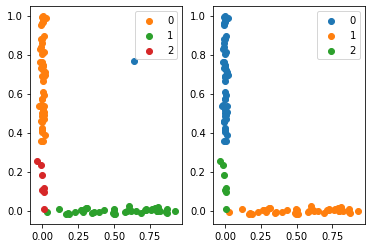

In [38]:
#dims = np.arange(0,10)[list(frequent_itemsets['itemsets'].to_numpy()[0])]
plt.subplot(1,2,1)

print(labels[labels>=0])
plt.scatter(X[ete, dims[0]], X[ete, dims[1]])
for i in range(len(set(labels[labels>=0]))):
    plt.scatter(x_normal[labels==i, dims[0]], x_normal[labels==i, dims[1]], label=i)
plt.legend()

plt.subplot(1,2,2)
x_ok = chooses[0][:, dims].sum(axis=1) == len(dims)
labels = cl.fit_predict(x_normal[x_ok][:, dims])
for i in range(len(set(labels[labels>=0]))):
    plt.scatter(x_normal[x_ok][labels==i, dims[0]], x_normal[x_ok][labels==i, dims[1]], label=i)
plt.legend()

plt.show()

In [133]:
centroids = np.empty((len(set(labels[labels>=0])), 1, x_normal.shape[1]))
for i in range(len(set(labels[labels>=0]))):
    centroids[i] = x_normal[x_ok][labels==i].mean(axis=0)

In [173]:
len(set(labels[labels>=0]))

8

In [4]:
# Compute the methoid of the cluster
def getMedoid(vX):
    vMean = np.mean(vX, axis=0)                               # compute centroid
    return vX[np.argmin([sum((x - vMean)**2) for x in vX])] 

In [175]:
centroids = np.empty((len(set(labels[labels>=0])), 1, x_normal.shape[1]))
for i in range(len(set(labels[labels>=0]))):
    centroids[i] = getMedoid(x_normal[x_ok][labels==i])

In [176]:
centroids.shape

(8, 1, 40)

In [177]:
# Define explainer 
from explainers import AETabularMMmd_ae
explainer = AETabularMMmd_ae.TabularMM(x_normal.shape[1], x_normal, [])
explainer([np.empty((1, x_normal.shape[1])), np.empty((1, x_normal.shape[1]))])
explainer.load_weights(os.path.join(path, f'exp_040_000_{ete[0]}.hdf5'))

160

If you intended to run this layer in float32, you can safely ignore this warning. If in doubt, this warning is likely only an issue if you are porting a TensorFlow 1.X model to TensorFlow 2.

To change all layers to have dtype float64 by default, call `tf.keras.backend.set_floatx('float64')`. To change just this layer, pass dtype='float64' to the layer constructor. If you are the author of this layer, you can disable autocasting by passing autocast=False to the base Layer constructor.



In [178]:
patches = []
#choose = np.zeros((1, x_normal.shape[1]))
#choose[:, dims] = 1.0
for c in centroids:
    choose = explainer.CHOOSE([X[ete], c])
    mask = explainer.MASK([X[ete], c])
    patches.append(explainer.MASKAPPLY([X[ete], mask, choose])[0])
patches = np.array(patches)

In [179]:
dims

[19, 23]

In [180]:
print(choose[:, 20:24])
print(mask[:, 20:24])

tf.Tensor([[7.8598314e-06 2.7910392e-05 5.4557113e-05 7.2223186e-01]], shape=(1, 4), dtype=float32)
tf.Tensor([[-2.4807622  -1.6206063  -1.4078931  -0.89986414]], shape=(1, 4), dtype=float32)


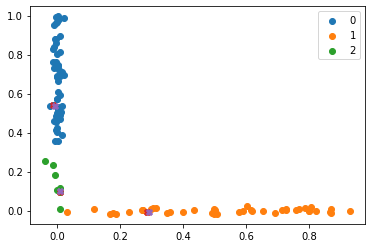

In [45]:
dims = np.arange(0,10)[list(frequent_itemsets['itemsets'].to_numpy()[0])]
labels = cl.fit_predict(x_normal[:, dims])
for i in range(len(set(labels[labels>=0]))):
    plt.scatter(x_normal[labels==i, dims[0]], x_normal[labels==i, dims[1]], label=i)
plt.scatter(centroids[:, 0, dims[0]], centroids[:, 0, dims[1]], marker='X')
plt.scatter(patches[:, dims[0]], patches[:, dims[1]], marker='X')
plt.legend()
plt.show()

In [180]:
patches

array([[ 0.34954858,  0.00922537,  0.4994082 ,  0.3829143 ,  0.76159877,
         0.09047467,  0.31937397, -0.00323442,  0.37081435,  0.04161706],
       [ 0.02760589,  0.4862652 ,  0.5629079 ,  0.3916851 ,  0.6111863 ,
         0.07981192,  0.26722768, -0.00200508,  0.36966038,  0.03807043],
       [-0.00759369,  0.85605854,  0.54219604,  0.38934425,  0.75756896,
         0.07111207,  0.34817618, -0.00601996,  0.33460832,  0.03395854]],
      dtype=float32)

In [181]:
from sklearn.ensemble import IsolationForest as IForest

if_s_s = IForest()
if_s_s.fit(X[:, dims])
for i in range(len(patches)):
    pos_l_a = if_s_s.score_samples(patches[i:i+1][:, dims])[0]
    pos_l_b = if_s_s.score_samples(X[ete][:, dims])[0]
    print(pos_l_a, pos_l_b)

-0.4631043093565688 -0.7603188018003818
-0.5690598965863872 -0.7603188018003818
-0.4962586033873534 -0.7603188018003818


# Collect results for evaluation

Here we collect the results for every point in every dataset using the pipeline wich includes the frequent itemset mining step and the clustering step

In [2]:
import pickle
from sklearn.neighbors import NearestNeighbors
from mlxtend.frequent_patterns import fpmax
from sklearn.cluster import DBSCAN
from explainers import AETabularMMmd_ae
import os
import pandas as pd
import numpy as np

In [3]:
# Compute the methoid of the cluster
def getMedoid(vX):
    vMean = np.mean(vX, axis=0)                               # compute centroid
    return vX[np.argmin([sum((x - vMean)**2) for x in vX])] 

In [ ]:
from sklearn.ensemble import IsolationForest as IForest

data_path = 'tests/logs/exp_data_20230509182512'
dataset_path = 'datasets/synthetic/processed/'

files = os.listdir(dataset_path)
files.sort()
for f in files:
    print(f)
    if not (f.startswith('info_') or ('100' in f)):
        chooses = pickle.load(open(os.path.join(data_path, f.replace('.csv', '_choose.joblib')),'rb'))
        data = pd.read_csv(os.path.join(dataset_path, f))
        
        X = data.iloc[:,:data.shape[1]-1].to_numpy()
        Y = data.iloc[:,-1].to_numpy()
        

        near_neigh = NearestNeighbors(n_neighbors=100)
        near_neigh.fit(X[Y == 0])
        
        
        explanations = []
        medoids = []
        patches = []
        
        i = 0
        for ete in np.argwhere(data['class'].to_numpy() != 0):
            point_exps = []
            point_meds = []
            point_patches = []
            
            print(f'Explaining point: {ete[0]}')
            
            # Calcolo i vicini
            _, y_normal = near_neigh.kneighbors(X[ete])
            x_normal = X[Y == 0][y_normal[0]]
            
            # Trovo gli itemset di features frequenti
            frequent_itemsets = fpmax(pd.DataFrame(chooses[i]), min_support = 0.25)
            
            for fit in frequent_itemsets['itemsets'].to_numpy():
                dims = list(fit)
                print(dims)
                
                # Clustering dei punti che sono coperti da quell'itemset 
                x_ok = chooses[i][:, dims].sum(axis=1) == len(dims)
                cl = DBSCAN(eps=0.10)
                labels = cl.fit_predict(x_normal[x_ok][:, dims])
                
                # Caricamento del modello 
                explainer = AETabularMMmd_ae.TabularMM(x_normal.shape[1], x_normal, [])
                explainer([np.empty((1, x_normal.shape[1]), dtype=np.float32), np.empty((1, x_normal.shape[1]), dtype=np.float32)])
                explainer.load_weights(os.path.join(data_path, f.replace('synth_multidim', 'exp').replace('.csv', f'_{ete[0]}.hdf5')))
                
                # Calcolo dei medoidi dei clusters e dei punti patchati
                mds = np.empty((len(set(labels[labels>=0])), 1, x_normal.shape[1]))
                ptc = np.empty((len(set(labels[labels>=0])), x_normal.shape[1]))
                for j in range(len(set(labels[labels>=0]))):
                    mds[j] = getMedoid(x_normal[x_ok][labels==j])
                    choose = explainer.CHOOSE([X[ete], mds[j]])
                    mask = explainer.MASK([X[ete], mds[j]])
                    ptc[j] = explainer.MASKAPPLY([X[ete], mask, choose])[0]
                    
                    
                # Salvataggio degli itemset e dei medoidi associati
                point_exps.append(fit)
                point_meds.append(mds)
                point_patches.append(ptc)
                
            # Aggiungo le spiegazioni ed i medoidi di quel punto alla lista generale
            explanations.append(point_exps)
            medoids.append(point_meds)
            patches.append(point_patches)
            
            i += 1
            
        pickle.dump(explanations, open(os.path.join(data_path, f'itemsets_{f.replace(".csv", ".joblib")}'), 'wb'))
        pickle.dump(medoids, open(os.path.join(data_path, f'medoids_{f.replace(".csv", ".joblib")}'), 'wb'))
        pickle.dump(patches, open(os.path.join(data_path, f'patches_{f.replace(".csv", ".joblib")}'), 'wb'))

info_synth_multidim_010_000.csv
info_synth_multidim_010_000.joblib
info_synth_multidim_010_001.csv
info_synth_multidim_010_001.joblib
info_synth_multidim_010_002.csv
info_synth_multidim_010_002.joblib
info_synth_multidim_020_000.csv
info_synth_multidim_020_000.joblib
info_synth_multidim_020_001.csv
info_synth_multidim_020_001.joblib
info_synth_multidim_020_002.csv
info_synth_multidim_020_002.joblib
info_synth_multidim_030_000.csv
info_synth_multidim_030_000.joblib
info_synth_multidim_030_001.csv
info_synth_multidim_030_001.joblib
info_synth_multidim_030_002.csv
info_synth_multidim_030_002.joblib
info_synth_multidim_040_000.csv
info_synth_multidim_040_000.joblib
info_synth_multidim_040_001.csv
info_synth_multidim_040_001.joblib
info_synth_multidim_040_002.csv
info_synth_multidim_040_002.joblib
info_synth_multidim_050_000.csv
info_synth_multidim_050_000.joblib
info_synth_multidim_050_001.csv
info_synth_multidim_050_001.joblib
info_synth_multidim_050_002.csv
info_synth_multidim_050_002.jo

/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(
2024-03-15 18:46:30.320104: I tensorflow/core/platform/cpu_feature_guard.cc:142] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN)to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-03-15 18:46:30.354574: I tensorflow/core/platform/profile_utils/cpu_utils.cc:104] CPU Frequency: 2300000000 Hz
2024-03-15 18:46:30.358779: I tensorflow/compiler/xla/service/service.cc:168] XLA service 0x1d74640 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
2024-03-15 18:46:30.358833: I ten

40


2024-03-15 18:46:31.482327: I tensorflow/stream_executor/platform/default/dso_loader.cc:48] Successfully opened dynamic library libcublas.so.10


Explaining point: 183
[0, 1]
40
Explaining point: 184
[6, 7]
40


...

[4]
160
[6]
160
Explaining point: 922
[8, 32]
160
[8, 37]
160


/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


Explaining point: 965
[18]
160
[3]
160


/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


[37]
160
[1]
160
[33]
160


# Collect results for alpha test 

## Collect explanations

In [5]:
# Compute the methoid of the cluster
def getMedoid(vX):
    vMean = np.mean(vX, axis=0)                               # compute centroid
    return vX[np.argmin([sum((x - vMean)**2) for x in vX])] 

In [11]:
import warnings
warnings.filterwarnings("ignore")

alpha = 1

data = {1: ['tests/logs/alpha1_0.8', 'tests/logs/alpha1_1.0', 'tests/logs/alpha1_1.2'],
        2: ['tests/logs/alpha2_0.8', 'tests/logs/alpha2_1.0', 'tests/logs/alpha2_1.2'],
        #2: ['tests/logs/alpha2_0.4', 'tests/logs/alpha2_0.5', 'tests/logs/alpha2_0.6', 'tests/logs/alpha2_0.7', 'tests/logs/alpha2_0.8'],
        3: ['tests/logs/alpha3_0.1', 'tests/logs/alpha3_0.3', 'tests/logs/alpha3_0.5']}
dataset_path = 'datasets/synthetic/processed/'

files = os.listdir(dataset_path)
files.sort()

data_paths = data[alpha]

for data_path in data_paths:
    for f in files:
        if not (f.startswith('info_') or ('100' in f)):
            print(f'----------- ALPHA: {data_path} -------- FILE: {f} -------------------')
            chooses = pickle.load(open(os.path.join(data_path, f.replace('.csv', '_choose.joblib')),'rb'))
            data = pd.read_csv(os.path.join(dataset_path, f))

            X = data.iloc[:,:data.shape[1]-1].to_numpy()
            Y = data.iloc[:,-1].to_numpy()


            near_neigh = NearestNeighbors(n_neighbors=100)
            near_neigh.fit(X[Y == 0])


            explanations = []
            medoids = []
            patches = []

            i = 0
            for ete in np.argwhere(data['class'].to_numpy() != 0):
                point_exps = []
                point_meds = []
                point_patches = []

                print(f'Explaining point: {ete[0]}')

                # Calcolo i vicini
                _, y_normal = near_neigh.kneighbors(X[ete])
                x_normal = X[Y == 0][y_normal[0]]

                # Trovo gli itemset di features frequenti
                frequent_itemsets = fpmax(pd.DataFrame(chooses[i]), min_support = 0.25)

                for fit in frequent_itemsets['itemsets'].to_numpy():
                    dims = list(fit)
                    #print(dims)

                    # Clustering dei punti che sono coperti da quell'itemset 
                    x_ok = chooses[i][:, dims].sum(axis=1) == len(dims)
                    cl = DBSCAN(eps=0.10)
                    labels = cl.fit_predict(x_normal[x_ok][:, dims])

                    # Caricamento del modello 
                    explainer = AETabularMMmd_ae.TabularMM(x_normal.shape[1], x_normal, [])
                    explainer([np.empty((1, x_normal.shape[1]), dtype=np.float32), np.empty((1, x_normal.shape[1]), dtype=np.float32)])
                    explainer.load_weights(os.path.join(data_path, f.replace('synth_multidim', 'exp').replace('.csv', f'_{ete[0]}.hdf5')))

                    # Calcolo dei medoidi dei clusters e dei punti patchati
                    if len(set(labels[labels>=0]))>0:
                        mds = np.empty((len(set(labels[labels>=0])), 1, x_normal.shape[1]))
                        ptc = np.empty((len(set(labels[labels>=0])), x_normal.shape[1]))
                        for j in range(len(set(labels[labels>=0]))):
                            mds[j] = getMedoid(x_normal[x_ok][labels==j])
                            #choose = explainer.CHOOSE([X[ete], mds[j]])
                            #mask = explainer.MASK([X[ete], mds[j]])
                            #ptc[j] = explainer.MASKAPPLY([X[ete], mask, choose])[0]
                            ptc[j], _ = explainer.explain([X[ete], mds[j]])
                    else:
                        # Se non trova cluster collassiamo tutto in un unico cluster
                        mds = np.empty((1, 1, x_normal.shape[1]))
                        ptc = np.empty((1, x_normal.shape[1]))
                        mds[0] = getMedoid(x_normal[x_ok])
                        #choose = explainer.CHOOSE([X[ete], mds[0]])
                        #mask = explainer.MASK([X[ete], mds[0]])
                        ptc[0], _ = explainer.explain([X[ete], mds[0]])
                        #ptc[0] = explainer.MASKAPPLY([X[ete], mask, choose])[0]


                    # Salvataggio degli itemset e dei medoidi associati
                    point_exps.append(fit)
                    point_meds.append(mds)
                    point_patches.append(ptc)

                # Aggiungo le spiegazioni ed i medoidi di quel punto alla lista generale
                explanations.append(point_exps)
                medoids.append(point_meds)
                patches.append(point_patches)

                i += 1

            pickle.dump(explanations, open(os.path.join(data_path, f'itemsets_{f.replace(".csv", ".joblib")}'), 'wb'))
            pickle.dump(medoids, open(os.path.join(data_path, f'medoids_{f.replace(".csv", ".joblib")}'), 'wb'))
            pickle.dump(patches, open(os.path.join(data_path, f'patches_{f.replace(".csv", ".joblib")}'), 'wb'))

----------- ALPHA: tests/logs/alpha1_0.8 -------- FILE: synth_multidim_010_000.csv -------------------


FileNotFoundError: [Errno 2] No such file or directory: 'tests/logs/alpha1_0.8/synth_multidim_010_000_choose.joblib'

# Results parameters tests

## Collect explanations

In [4]:
# Compute the methoid of the cluster
def getMedoid(vX):
    vMean = np.mean(vX, axis=0)                               # compute centroid
    return vX[np.argmin([sum((x - vMean)**2) for x in vX])] 

In [13]:
par = 'ee'

data = {'ee': ['tests/logs/epochs_test_20', 'tests/logs/epochs_test_40'],
        'no': ['tests/logs/no_test_60', 'tests/logs/no_test_140'],
        'eb': ['tests/logs/batch_test_8', 'tests/logs/batch_test_32'],
        'lr': ['tests/logs/lr_test_0.0005', 'tests/logs/lr_test_0.002']
       }
dataset_path = 'datasets/synthetic/processed/'

files = os.listdir(dataset_path)
files.sort()

data_paths = data[par]

for data_path in data_paths:
    for f in files:
        print(f)
        if not (f.startswith('info_') or ('100' in f)):
            chooses = pickle.load(open(os.path.join(data_path, f.replace('.csv', '_choose.joblib')),'rb'))
            data = pd.read_csv(os.path.join(dataset_path, f))

            X = data.iloc[:,:data.shape[1]-1].to_numpy()
            Y = data.iloc[:,-1].to_numpy()
            
            
            if par == 'no':
                nneig = int(data_path.split('_')[-1])
                print(nneig)
            else:
                nneig = 100
            
            near_neigh = NearestNeighbors(n_neighbors=nneig)
            near_neigh.fit(X[Y == 0])


            explanations = []
            medoids = []
            patches = []

            i = 0
            for ete in np.argwhere(data['class'].to_numpy() != 0):
                point_exps = []
                point_meds = []
                point_patches = []

                print(f'Explaining point: {ete[0]}')

                # Calcolo i vicini
                _, y_normal = near_neigh.kneighbors(X[ete])
                x_normal = X[Y == 0][y_normal[0]]

                # Trovo gli itemset di features frequenti
                frequent_itemsets = fpmax(pd.DataFrame(chooses[i]), min_support = 0.25)

                for fit in frequent_itemsets['itemsets'].to_numpy():
                    dims = list(fit)
                    print(dims)

                    # Clustering dei punti che sono coperti da quell'itemset 
                    x_ok = chooses[i][:, dims].sum(axis=1) == len(dims)
                    cl = DBSCAN(eps=0.10)
                    labels = cl.fit_predict(x_normal[x_ok][:, dims])

                    # Caricamento del modello 
                    explainer = AETabularMMmd_ae.TabularMM(x_normal.shape[1], x_normal, [])
                    explainer([np.empty((1, x_normal.shape[1]), dtype=np.float32), np.empty((1, x_normal.shape[1]), dtype=np.float32)])
                    explainer.load_weights(os.path.join(data_path, f.replace('synth_multidim', 'exp').replace('.csv', f'_{ete[0]}.hdf5')))

                    # Calcolo dei medoidi dei clusters e dei punti patchati
                    if len(set(labels[labels>=0]))>0:
                        mds = np.empty((len(set(labels[labels>=0])), 1, x_normal.shape[1]))
                        ptc = np.empty((len(set(labels[labels>=0])), x_normal.shape[1]))
                        for j in range(len(set(labels[labels>=0]))):
                            mds[j] = getMedoid(x_normal[x_ok][labels==j])
                            #choose = explainer.CHOOSE([X[ete], mds[j]])
                            #mask = explainer.MASK([X[ete], mds[j]])
                            #ptc[j] = explainer.MASKAPPLY([X[ete], mask, choose])[0]
                            ptc[j], _ = explainer.explain([X[ete], mds[j]])
                    else:
                        # Se non trova cluster collassiamo tutto in un unico cluster
                        mds = np.empty((1, 1, x_normal.shape[1]))
                        ptc = np.empty((1, x_normal.shape[1]))
                        mds[0] = getMedoid(x_normal[x_ok])
                        #choose = explainer.CHOOSE([X[ete], mds[0]])
                        #mask = explainer.MASK([X[ete], mds[0]])
                        ptc[0], _ = explainer.explain([X[ete], mds[0]])
                        #ptc[0] = explainer.MASKAPPLY([X[ete], mask, choose])[0]


                    # Salvataggio degli itemset e dei medoidi associati
                    point_exps.append(fit)
                    point_meds.append(mds)
                    point_patches.append(ptc)

                # Aggiungo le spiegazioni ed i medoidi di quel punto alla lista generale
                explanations.append(point_exps)
                medoids.append(point_meds)
                patches.append(point_patches)

                i += 1

            pickle.dump(explanations, open(os.path.join(data_path, f'itemsets_{f.replace(".csv", ".joblib")}'), 'wb'))
            pickle.dump(medoids, open(os.path.join(data_path, f'medoids_{f.replace(".csv", ".joblib")}'), 'wb'))
            pickle.dump(patches, open(os.path.join(data_path, f'patches_{f.replace(".csv", ".joblib")}'), 'wb'))

info_synth_multidim_010_000.csv
info_synth_multidim_010_000.joblib
info_synth_multidim_010_001.csv
info_synth_multidim_010_001.joblib
info_synth_multidim_010_002.csv
info_synth_multidim_010_002.joblib
info_synth_multidim_020_000.csv
info_synth_multidim_020_000.joblib
info_synth_multidim_020_001.csv
info_synth_multidim_020_001.joblib
info_synth_multidim_020_002.csv
info_synth_multidim_020_002.joblib
info_synth_multidim_030_000.csv
info_synth_multidim_030_000.joblib
info_synth_multidim_030_001.csv
info_synth_multidim_030_001.joblib
info_synth_multidim_030_002.csv
info_synth_multidim_030_002.joblib
info_synth_multidim_040_000.csv
info_synth_multidim_040_000.joblib
info_synth_multidim_040_001.csv
info_synth_multidim_040_001.joblib
info_synth_multidim_040_002.csv
info_synth_multidim_040_002.joblib
info_synth_multidim_050_000.csv
info_synth_multidim_050_000.joblib
info_synth_multidim_050_001.csv
info_synth_multidim_050_001.joblib
info_synth_multidim_050_002.csv
info_synth_multidim_050_002.jo

/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(
/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


RATIO:  [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
RATIO:  [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
Explaining point: 184
[6, 7]
40
RATIO:  [0. 0. 0. 0. 0. 0. 1. 1. 0. 0.]
Explaining point: 207
[0, 1]
40
RATIO:  [1. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
RATIO:  [1. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
Explaining point: 220
[3, 5]
40


/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(
/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(
/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


RATIO:  [0. 0. 0. 1. 0. 1. 0. 0. 0. 0.]
RATIO:  [0. 0. 0. 1. 0. 1. 0. 0. 0. 0.]
[4, 5]
40
RATIO:  [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
RATIO:  [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
Explaining point: 245
[3, 4, 5]
40
RATIO:  [0. 0. 0. 1. 1. 0. 0. 0. 0. 0.]
RATIO:  [0. 0. 0. 1. 1. 0. 0. 0. 0. 0.]
Explaining point: 315
[0, 1, 6]
40


...

/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(
/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


RATIO:  [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0.]
Explaining point: 984
[28, 39, 47]
300
RATIO:  [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0.]
RATIO:  [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0.]
Explaining point: 989
[65, 55, 63]
300


/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(
/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


RATIO:  [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0.
 0. 0. 0.]
Explaining point: 990
[24, 8, 27]
300
RATIO:  [0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 1. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0.]
Explaining point: 999
[16, 47]
300
RATIO:  [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0.]
RATIO:  [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0

/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


# Collect results for real data sets


## Collect explanations

In [3]:
# Compute the methoid of the cluster
def getMedoid(vX):
    vMean = np.mean(vX, axis=0)                               # compute centroid
    return vX[np.argmin([sum((x - vMean)**2) for x in vX])] 

In [6]:
#dataset_paths = {'cardio': 'cardio_1685605801.579052',
#             'breast': 'breast_1685605801.3900645',
#             'ionosphere': 'ionosphere_1685605801.3333552',
#             'arrhythmia': 'arrhythmia_1685605801.5731122',
#            'musk': 'musk_1685605801.362368'}

# alpha 3 = 0.3
#dataset_paths = {'cardio': 'cardio_1685699043.676444',
#             'breast': 'breast_1685699044.071625',
#             'ionosphere': 'ionosphere_1685699044.134206',
#             'arrhythmia': 'arrhythmia_1685700206.786617',
#            'musk': 'musk_1685699043.5538688'}

#dataset_paths = {'cardio': 'cardio_1685705739.3934853',
#             'breast': 'breast_1685705739.3628566',
#             'ionosphere': 'ionosphere_1685705739.0082045',
#             'arrhythmia': 'arrhythmia_1685707915.3712327',
#            'musk': 'musk_1685705739.223749'}

#dataset_paths = {'cardio': 'cardio_1685801943.9156919',
#             'breast': 'breast_1685801943.3232358',
#             'ionosphere': 'ionosphere_1685801943.5839376',
#             'arrhythmia': 'arrhythmia_1685801943.55852',
#            'musk': 'musk_1685801943.9017832'}

# Multi run
dataset_paths = {'cardio': 'cardio_1685828451.2208996',
             'breast': 'breast_1685828451.6128614',
             'ionosphere': 'ionosphere_1685828450.8401275',
             'arrhythmia': 'arrhythmia_1685828451.617122',
            'musk': 'musk_1685828451.6472118',
                'ionosphere_sub': 'ionosphere_sub_1711558782.0051067',
                'musk_sub': 'musk_sub_1711558756.0638723'}

test = 'tests/logs'

datasets = ['ionosphere_sub', 'musk_sub']


for dataset in datasets:
    print('-----', dataset, '-----')
    for r in range(1):
        print('R: ', r)
        data_path = os.path.join(test, dataset_paths[dataset])
        data = pd.read_csv(f'datasets/data/{dataset}.csv')
        chooses = pickle.load(open(os.path.join(data_path, f'choose_{r}.joblib'),'rb'))

        X = data.iloc[:,:data.shape[1]-1].to_numpy()
        Y = data.iloc[:,-1].to_numpy()

        near_neigh = NearestNeighbors(n_neighbors=30)
        near_neigh.fit(X[Y == 0])

        explanations = []
        medoids = []
        patches = []

        i = 0
        for ete in np.argwhere(Y == 1):
            point_exps = []
            point_meds = []
            point_patches = []

            print(f'Explaining point: {ete[0]}')

            # Calcolo i vicini
            _, y_normal = near_neigh.kneighbors(X[ete])
            x_normal = X[Y == 0][y_normal[0]]

            # Trovo gli itemset di features frequenti
            frequent_itemsets = fpmax(pd.DataFrame(chooses[i]), min_support = 0.25)
            #print(chooses[i].mean(axis=0))

            for fit in frequent_itemsets['itemsets'].to_numpy():
                dims = list(fit)
                print(dims)

                # Clustering dei punti che sono coperti da quell'itemset 
                x_ok = chooses[i][:, dims].sum(axis=1) == len(dims)
                cl = DBSCAN(eps=0.10)
                labels = cl.fit_predict(x_normal[x_ok][:, dims])

                # Caricamento del modello 
                explainer = AETabularMMmd_ae.TabularMM(x_normal.shape[1], x_normal, [])
                explainer([np.empty((1, x_normal.shape[1]), dtype=np.float32), np.empty((1, x_normal.shape[1]), dtype=np.float32)])
                explainer.load_weights(os.path.join(data_path, f'exp_{dataset}_{ete[0]}_{r}.hdf5'))

                # Calcolo dei medoidi dei clusters e dei punti patchati
                if len(set(labels[labels>=0]))>0:
                    mds = np.empty((len(set(labels[labels>=0])), 1, x_normal.shape[1]))
                    ptc = np.empty((len(set(labels[labels>=0])), x_normal.shape[1]))
                    for j in range(len(set(labels[labels>=0]))):
                        mds[j] = getMedoid(x_normal[x_ok][labels==j])
                        ptc[j], _ = explainer.explain([X[ete], mds[j]])
                else:
                    # Se non trova cluster collassiamo tutto in un unico cluster
                    mds = np.empty((1, 1, x_normal.shape[1]))
                    ptc = np.empty((1, x_normal.shape[1]))
                    mds[0] = getMedoid(x_normal[x_ok])
                    ptc[0], _ = explainer.explain([X[ete], mds[0]])


                # Salvataggio degli itemset e dei medoidi associati
                point_exps.append(fit)
                point_meds.append(mds)
                point_patches.append(ptc)

            # Aggiungo le spiegazioni ed i medoidi di quel punto alla lista generale
            explanations.append(point_exps)
            medoids.append(point_meds)
            patches.append(point_patches)

            i += 1

        pickle.dump(explanations, open(os.path.join(data_path, f'itemsets_{dataset}_{r}'), 'wb'))
        pickle.dump(medoids, open(os.path.join(data_path, f'medoids_{dataset}_{r}'), 'wb'))
        pickle.dump(patches, open(os.path.join(data_path, f'patches_{dataset}_{r}'), 'wb'))

----- ionosphere_sub -----
R:  0
Explaining point: 1
[1, 3, 5, 6, 8]
40
RATIO:  [0. 1. 0. 1. 0. 1. 1. 0. 1. 0.]
Explaining point: 3
[2, 3, 5]
40


/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(
/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


RATIO:  [0. 0. 1. 1. 0. 1. 0. 0. 0. 0.]
Explaining point: 5
[3, 4, 5, 6, 7, 8]
40
RATIO:  [0. 0. 0. 1. 1. 1. 1. 1. 1. 0.]
Explaining point: 7
[2, 3, 4, 7]
40


/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(
/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


RATIO:  [0. 0. 1. 1. 1. 0. 0. 1. 0. 0.]
Explaining point: 9
[1, 4, 5, 6, 7, 9]
40
RATIO:  [0. 1. 0. 0. 1. 1. 1. 1. 0. 1.]
Explaining point: 11
[8, 1, 3]
40
RATIO:  [0. 1. 0. 1. 0. 0. 0. 0. 1. 0.]
Explaining point: 13
[8, 1]
40


...

RATIO:  [0. 0. 1. 0. 0. 0. 0. 0. 0. 1.]
Explaining point: 91
[1]
40
RATIO:  [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
Explaining point: 92
[8, 2]
40
RATIO:  [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
Explaining point: 93
[2, 7]
40


/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(
/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(
/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


RATIO:  [0. 0. 1. 0. 0. 0. 0. 1. 0. 0.]
Explaining point: 94
[1, 2, 5]
40
RATIO:  [0. 1. 1. 0. 0. 0. 0. 0. 0. 0.]
Explaining point: 95
[2]
40
RATIO:  [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
Explaining point: 96
[8, 2]
40


/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(
/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(
/home/simona/Simona/MaskingModels/mm_venv/lib/python3.8/site-packages/mlxtend/frequent_patterns/fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


RATIO:  [0. 0. 1. 0. 0. 0. 0. 0. 1. 0.]
